In [1]:
import pandas as pd
import numpy as np
import torch
import shap
import itertools
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import torch.nn.functional as F
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_squared_error
import os
from scipy.interpolate import UnivariateSpline



In [4]:
# 1. Load data  to the 'Ug' column
data_df = pd.read_excel("dataset/dataset_training.xlsx")

# Separate data into input and output
X = data_df.drop(columns=['εs','C/C0']).values
y = data_df[['εs', 'C/C0']].values
scaler = StandardScaler()
X_normalized = scaler.fit_transform(X)
X_tensor = torch.tensor(X_normalized, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)  # y应该是一个包含两列的数组

# Define the number of splits for K-Fold cross-validation
n_splits = 5
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Prepare to collect the cross-validation results
cv_results = {
    'train_loss': [],
    'val_loss': [],
    'val_r2': [],
    'val_mse': []
}

In [5]:
data_df

,r/R,H,DT,H0,Ug,εs,C/C0
0,0.00,0.25,76,1.0,0.3,0.2696,0.425829
1,0.00,0.56,76,1.0,0.3,0.2772,0.272967
2,0.00,1.02,76,1.0,0.3,0.2776,0.187622
3,0.00,1.47,76,1.0,0.3,0.2102,0.112218
4,0.00,1.93,76,1.0,0.3,0.0163,0.124415
...,...,...,...,...,...,...,...
529,0.95,1.04,152,1.0,1.0,0.3820,0.311235
530,0.95,1.30,152,1.0,1.0,0.3138,0.258406
531,0.95,1.55,152,1.0,1.0,0.2131,0.214758
532,0.95,1.80,152,1.0,1.0,0.1045,0.165599


In [6]:
# 2. Define and train the PyTorch neural network model
class AdjustedRegressionModel(nn.Module):
    def __init__(self, input_dim):
        super(AdjustedRegressionModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, 10)
        self.fc2 = nn.Linear(10, 15)
        self.fc3 = nn.Linear(15, 20)
        self.fc4 = nn.Linear(20, 25)
        self.fc5 = nn.Linear(25, 30)
        self.fc6 = nn.Linear(30, 30)
        self.fc7 = nn.Linear(30, 30)
        self.fc8 = nn.Linear(30, 30)
        self.fc9 = nn.Linear(30, 25)
        self.fc10 = nn.Linear(25, 20)
        self.fc11 = nn.Linear(20, 15)
        self.fc12 = nn.Linear(15, 2) # 输出层维度为2，对应εs'和C/C0
        self.leaky_relu = nn.LeakyReLU(negative_slope=0.01)
        self.sigmoid = nn.Sigmoid()  # Sigmoid激活函数将输出限制在(0,1)

    def forward(self, x):
        x = self.leaky_relu(self.fc1(x))
        x = self.leaky_relu(self.fc2(x))
        x = self.leaky_relu(self.fc3(x))
        x = self.leaky_relu(self.fc4(x))
        x = self.leaky_relu(self.fc5(x))
        x = self.leaky_relu(self.fc6(x))
        x = self.leaky_relu(self.fc7(x))
        x = self.leaky_relu(self.fc8(x))
        x = self.leaky_relu(self.fc9(x))
        x = self.leaky_relu(self.fc10(x))
        x = self.leaky_relu(self.fc11(x))
        x = self.sigmoid(self.fc12(x))  # 应用Sigmoid激活函数
        return x

# Training with early stopping
num_epochs = 300
batch_size = 72
train_losses = []
val_losses = []
best_val_loss = float('inf')
patience, trials = 50, 20

FOLD 1
---------------------


C:\Anaconda\envs\pytorch\Lib\site-packages\torch\optim\lr_scheduler.py:60: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Early stopping on fold 1, epoch 262
Best validation loss for fold 1: 0.0009506689384579659
Best validation R2 for fold 1: 0.94342041015625
Best validation MSE for fold 1: 0.000931764196138829
FOLD 2
---------------------


C:\Anaconda\envs\pytorch\Lib\site-packages\torch\optim\lr_scheduler.py:60: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Early stopping on fold 2, epoch 236
Best validation loss for fold 2: 0.0008510371262673289
Best validation R2 for fold 2: 0.9515862166881561
Best validation MSE for fold 2: 0.0008381453808397055
FOLD 3
---------------------


...

Early stopping on fold 3, epoch 191
Best validation loss for fold 3: 0.0012213118025101721
Best validation R2 for fold 3: 0.9397450685501099
Best validation MSE for fold 3: 0.0011503829155117273
FOLD 4
---------------------


C:\Anaconda\envs\pytorch\Lib\site-packages\torch\optim\lr_scheduler.py:60: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Early stopping on fold 4, epoch 227
Best validation loss for fold 4: 0.0008494615904055536
Best validation R2 for fold 4: 0.9482786655426025
Best validation MSE for fold 4: 0.000823766109533608
FOLD 5
---------------------


C:\Anaconda\envs\pytorch\Lib\site-packages\torch\optim\lr_scheduler.py:60: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Early stopping on fold 5, epoch 245
Best validation loss for fold 5: 0.0009503642213530838
Best validation R2 for fold 5: 0.9445601403713226
Best validation MSE for fold 5: 0.0009433463565073907


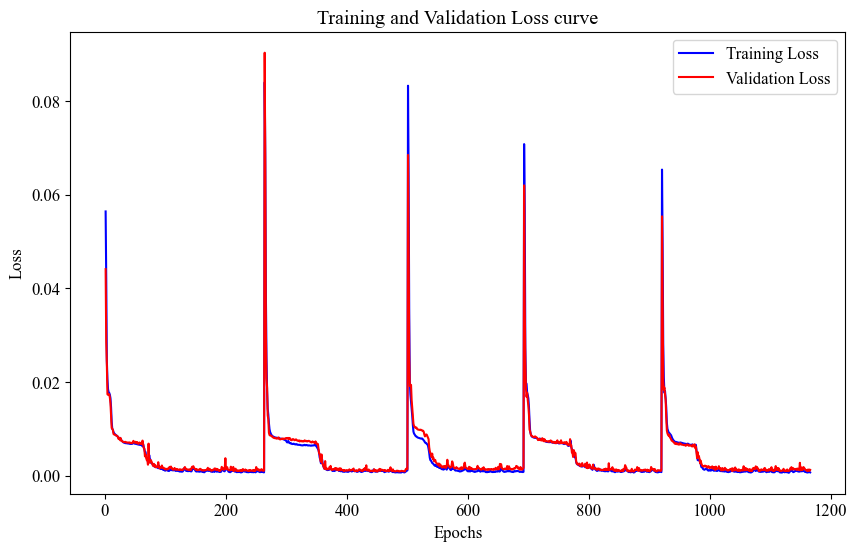

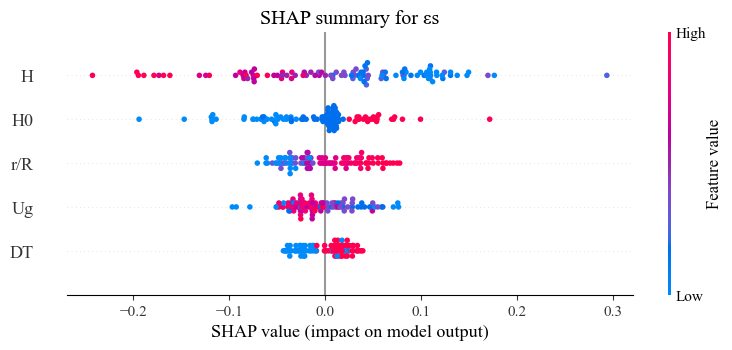

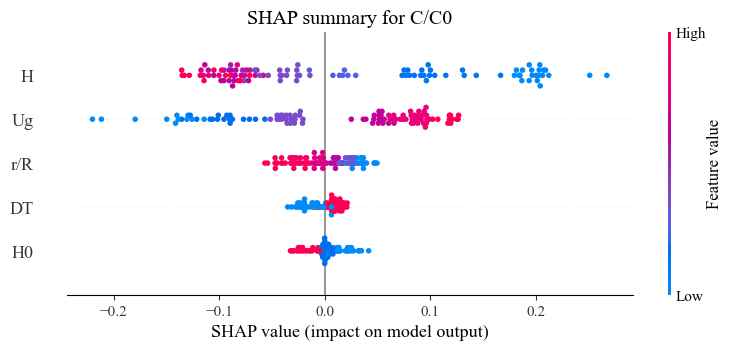

---------------------
Average train loss: 0.0037229712151107845
Average validation loss: 0.0009645687357988208
Average validation R2: 0.9455181002616883
Average validation MSE: 0.0009374809917062521


In [27]:
# Cross-validation loop
shap_data = []  # 用于存储每个fold的SHAP值数据


for fold, (train_index, val_index) in enumerate(kf.split(X_tensor.numpy()), 1):
    print(f"FOLD {fold}")
    print("---------------------")
    
    # Split the data into current training and validation sets
    X_train = X_tensor[train_index]
    y_train = y_tensor[train_index]
    X_val = X_tensor[val_index]
    y_val = y_tensor[val_index]
    
    # Create data loaders for the current fold
    train_dataset = TensorDataset(X_train, y_train)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_dataset = TensorDataset(X_val, y_val)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    
    # Initialize the model for the current fold
    model = AdjustedRegressionModel(X_train.shape[1])
    criterion = nn.MSELoss()
    optimizer = optim.AdamW(model.parameters(), lr=0.005, weight_decay=0.4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=10, factor=0.5, verbose=True)
    
    # Initialize variables for early stopping for the current fold
    best_val_loss = float('inf')
    
    # Training loop for the current fold
    for epoch in range(num_epochs):
        model.train()
        total_train_loss = 0
        for inputs, targets in train_loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1)  # Gradient clipping
            optimizer.step()
            total_train_loss += loss.item()
        train_losses.append(total_train_loss / len(train_loader))
        
        # Evaluate on the validation set for the current fold
        model.eval()
        total_val_loss = 0
        with torch.no_grad():
            for inputs, targets in val_loader:
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                total_val_loss += loss.item()
        
        # Calculate validation metrics for the current fold
        val_loss = total_val_loss / len(val_loader)
        val_losses.append(val_loss)
        val_predictions = torch.cat([model(inputs).detach() for inputs, _ in val_loader])
        
        val_r2_es = r2_score(y_val.numpy()[:, 0], val_predictions.numpy()[:, 0])
        val_r2_cc0 = r2_score(y_val.numpy()[:, 1], val_predictions.numpy()[:, 1])
        val_r2 = (val_r2_es + val_r2_cc0) / 2  # 计算平均R2分数

        val_mse_es = mean_squared_error(y_val.numpy()[:, 0], val_predictions.numpy()[:, 0])
        val_mse_cc0 = mean_squared_error(y_val.numpy()[:, 1], val_predictions.numpy()[:, 1])
        val_mse = (val_mse_es + val_mse_cc0) / 2  # 计算平均MSE分数
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_val_r2 = val_r2  # 记录最佳模型时的R2
            best_val_mse = val_mse  # 记录最佳模型时的MSE
            # 保存当前模型的参数
            best_model_state = model.state_dict()
            trials = 0
        else:
            trials += 1
            if trials >= patience:
                print(f"Early stopping on fold {fold}, epoch {epoch}")
                break
            
    
    
    cv_results['val_loss'].append(best_val_loss)
    cv_results['train_loss'].append(train_losses)
    cv_results['val_r2'].append(best_val_r2)
    cv_results['val_mse'].append(best_val_mse)
    
    print(f"Best validation loss for fold {fold}: {best_val_loss}")
    print(f"Best validation R2 for fold {fold}: {best_val_r2}")
    print(f"Best validation MSE for fold {fold}: {best_val_mse}")
   
    
    # 使用SHAP进行模型解释
    explainer = shap.GradientExplainer(model, X_train)
    shap_values = explainer.shap_values(X_val)
    shap_values = shap_values.transpose(2, 0, 1)

    # 存储SHAP值数据
    for i, output_name in enumerate(['εs', 'C/C0']):
        shap_df = pd.DataFrame(shap_values[i], columns=['Feature_' + str(j) for j in range(X_val.shape[1])])
        shap_df['Output'] = output_name
        shap_df['Fold'] = fold
        shap_data.append(shap_df)

# 将SHAP值保存到Excel
final_shap_df = pd.concat(shap_data, ignore_index=True)
# final_shap_df.to_excel('test_shap4_values0218.xlsx', sheet_name='SHAP Values', index=False)

# 绘制 loss 曲线
# 设置字体为新罗马
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12  # 可以调整字体大小
plt.figure(figsize=(10, 6))
epochs = range(1, len(train_losses) + 1)
plt.plot(epochs, train_losses, 'b-', label='Training Loss')
epochs = range(1, len(val_losses) + 1)
plt.plot(epochs, val_losses, 'r-', label='Validation Loss')

plt.title('Training and Validation Loss curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
#plt.grid(True)

# 保存图像
#plt.savefig('0218loss_curves.png')
#plt.savefig('0218loss_curves.pdf')
plt.show()



# 可视化部分
for i, output_name in enumerate(['εs', 'C/C0']):
    plt.figure()
    shap.summary_plot(shap_values[i], X_val.numpy(), feature_names=['r/R', 'H', 'DT', 'H0', 'Ug'], show=False)
    plt.title(f'SHAP summary for {output_name}')
    plt.show()
   

# Display average metrics across folds
print("---------------------")
print(f"Average train loss: {np.mean(cv_results['train_loss'])}")
print(f"Average validation loss: {np.mean(cv_results['val_loss'])}")
print(f"Average validation R2: {np.mean(cv_results['val_r2'])}")
print(f"Average validation MSE: {np.mean(cv_results['val_mse'])}")

In [7]:
class RegressionModel_ReLU(nn.Module):
    def __init__(self, input_dim):
        super(RegressionModel_ReLU, self).__init__()
        self.fc1 = nn.Linear(input_dim, 10)
        self.fc2 = nn.Linear(10, 15)
        self.fc3 = nn.Linear(15, 20)
        self.fc4 = nn.Linear(20, 25)
        self.fc5 = nn.Linear(25, 30)
        self.fc6 = nn.Linear(30, 30)
        self.fc7 = nn.Linear(30, 30)
        self.fc8 = nn.Linear(30, 30)
        self.fc9 = nn.Linear(30, 25)
        self.fc10 = nn.Linear(25, 20)
        self.fc11 = nn.Linear(20, 15)
        self.fc12 = nn.Linear(15, 2) 
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.relu(self.fc4(x))
        x = self.relu(self.fc5(x))
        x = self.relu(self.fc6(x))
        x = self.relu(self.fc7(x))
        x = self.relu(self.fc8(x))
        x = self.relu(self.fc9(x))
        x = self.relu(self.fc10(x))
        x = self.relu(self.fc11(x))
        x = self.sigmoid(self.fc12(x))  # 应用Sigmoid激活函数
        return x
    
class RegressionModel_Without_Sigmoid(nn.Module):
    def __init__(self, input_dim):
        super(RegressionModel_Without_Sigmoid, self).__init__()
        self.fc1 = nn.Linear(input_dim, 10)
        self.fc2 = nn.Linear(10, 15)
        self.fc3 = nn.Linear(15, 20)
        self.fc4 = nn.Linear(20, 25)
        self.fc5 = nn.Linear(25, 30)
        self.fc6 = nn.Linear(30, 30)
        self.fc7 = nn.Linear(30, 30)
        self.fc8 = nn.Linear(30, 30)
        self.fc9 = nn.Linear(30, 25)
        self.fc10 = nn.Linear(25, 20)
        self.fc11 = nn.Linear(20, 15)
        self.fc12 = nn.Linear(15, 2) 
        self.leaky_relu = nn.LeakyReLU(negative_slope=0.01)

    def forward(self, x):
        x = self.leaky_relu(self.fc1(x))
        x = self.leaky_relu(self.fc2(x))
        x = self.leaky_relu(self.fc3(x))
        x = self.leaky_relu(self.fc4(x))
        x = self.leaky_relu(self.fc5(x))
        x = self.leaky_relu(self.fc6(x))
        x = self.leaky_relu(self.fc7(x))
        x = self.leaky_relu(self.fc8(x))
        x = self.leaky_relu(self.fc9(x))
        x = self.leaky_relu(self.fc10(x))
        x = self.leaky_relu(self.fc11(x))
        x = self.leaky_relu(self.fc12(x))
        return x
    
class RegressionModel_ELU(nn.Module):
    def __init__(self, input_dim):
        super(RegressionModel_ELU, self).__init__()
        self.fc1 = nn.Linear(input_dim, 10)
        self.fc2 = nn.Linear(10, 15)
        self.fc3 = nn.Linear(15, 20)
        self.fc4 = nn.Linear(20, 25)
        self.fc5 = nn.Linear(25, 30)
        self.fc6 = nn.Linear(30, 30)
        self.fc7 = nn.Linear(30, 30)
        self.fc8 = nn.Linear(30, 30)
        self.fc9 = nn.Linear(30, 25)
        self.fc10 = nn.Linear(25, 20)
        self.fc11 = nn.Linear(20, 15)
        self.fc12 = nn.Linear(15, 2) 
        self.elu = nn.ELU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.elu(self.fc1(x))
        x = self.elu(self.fc2(x))
        x = self.elu(self.fc3(x))
        x = self.elu(self.fc4(x))
        x = self.elu(self.fc5(x))
        x = self.elu(self.fc6(x))
        x = self.elu(self.fc7(x))
        x = self.elu(self.fc8(x))
        x = self.elu(self.fc9(x))
        x = self.elu(self.fc10(x))
        x = self.elu(self.fc11(x))
        x = self.sigmoid(self.fc12(x))
        return x
    
class RegressionModel_GELU(nn.Module):
    def __init__(self, input_dim):
        super(RegressionModel_GELU, self).__init__()
        self.fc1 = nn.Linear(input_dim, 10)
        self.fc2 = nn.Linear(10, 15)
        self.fc3 = nn.Linear(15, 20)
        self.fc4 = nn.Linear(20, 25)
        self.fc5 = nn.Linear(25, 30)
        self.fc6 = nn.Linear(30, 30)
        self.fc7 = nn.Linear(30, 30)
        self.fc8 = nn.Linear(30, 30)
        self.fc9 = nn.Linear(30, 25)
        self.fc10 = nn.Linear(25, 20)
        self.fc11 = nn.Linear(20, 15)
        self.fc12 = nn.Linear(15, 2) 
        self.gelu = nn.GELU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.gelu(self.fc1(x))
        x = self.gelu(self.fc2(x))
        x = self.gelu(self.fc3(x))
        x = self.gelu(self.fc4(x))
        x = self.gelu(self.fc5(x))
        x = self.gelu(self.fc6(x))
        x = self.gelu(self.fc7(x))
        x = self.gelu(self.fc8(x))
        x = self.gelu(self.fc9(x))
        x = self.gelu(self.fc10(x))
        x = self.gelu(self.fc11(x))
        x = self.sigmoid(self.fc12(x))
        return x
    
class RegressionModel_Tanh(nn.Module):
    def __init__(self, input_dim):
        super(RegressionModel_Tanh, self).__init__()
        self.fc1 = nn.Linear(input_dim, 10)
        self.fc2 = nn.Linear(10, 15)
        self.fc3 = nn.Linear(15, 20)
        self.fc4 = nn.Linear(20, 25)
        self.fc5 = nn.Linear(25, 30)
        self.fc6 = nn.Linear(30, 30)
        self.fc7 = nn.Linear(30, 30)
        self.fc8 = nn.Linear(30, 30)
        self.fc9 = nn.Linear(30, 25)
        self.fc10 = nn.Linear(25, 20)
        self.fc11 = nn.Linear(20, 15)
        self.fc12 = nn.Linear(15, 2)
        self.tanh = nn.Tanh()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.tanh(self.fc1(x))
        x = self.tanh(self.fc2(x))
        x = self.tanh(self.fc3(x))
        x = self.tanh(self.fc4(x))
        x = self.tanh(self.fc5(x))
        x = self.tanh(self.fc6(x))
        x = self.tanh(self.fc7(x))
        x = self.tanh(self.fc8(x))
        x = self.tanh(self.fc9(x))
        x = self.tanh(self.fc10(x))
        x = self.tanh(self.fc11(x))
        x = self.sigmoid(self.fc12(x))
        return x
    
# Training with early stopping
num_epochs = 300
batch_size = 72
train_losses = []
val_losses = []
best_val_loss = float('inf')
patience, trials = 50, 20

In [9]:
# 定义模型列表，包含不同的激活函数模型
model_variants = {
    'ReLU': RegressionModel_ReLU,
    'ELU': RegressionModel_ELU,
    'GELU': RegressionModel_GELU,
    'Tanh': RegressionModel_Tanh,
    'Without_Sigmoid': RegressionModel_Without_Sigmoid
}

# 初始化cv_results字典，准备每个激活函数的存储空间
cv_results = {}
for activation_fn in model_variants.keys():
    cv_results[f'{activation_fn}_val_loss'] = []
    cv_results[f'{activation_fn}_train_loss'] = []
    cv_results[f'{activation_fn}_val_r2'] = []
    cv_results[f'{activation_fn}_val_mse'] = []
    
# Cross-validation loop
for fold, (train_index, val_index) in enumerate(kf.split(X_tensor.numpy()), 1):
    print(f"FOLD {fold}")
    print("---------------------")
    
    # Split the data into current training and validation sets
    X_train = X_tensor[train_index]
    y_train = y_tensor[train_index]
    X_val = X_tensor[val_index]
    y_val = y_tensor[val_index]
    
    # Create data loaders for the current fold
    train_dataset = TensorDataset(X_train, y_train)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_dataset = TensorDataset(X_val, y_val)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    
    for activation_fn, ModelClass in model_variants.items():
        print(f"Training with {activation_fn} activation function")
        
        # Initialize the model for the current fold with the specific activation function
        model = ModelClass(X_train.shape[1])
        criterion = nn.MSELoss()
        optimizer = optim.AdamW(model.parameters(), lr=0.005, weight_decay=0.4)
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=10, factor=0.5, verbose=True)

        # Initialize variables for early stopping for the current fold
        best_val_loss = float('inf')

        # Training loop for the current fold
        for epoch in range(num_epochs):
            model.train()
            total_train_loss = 0
            for inputs, targets in train_loader:
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1)  # Gradient clipping
                optimizer.step()
                total_train_loss += loss.item()
            train_losses.append(total_train_loss / len(train_loader))

            # Evaluate on the validation set for the current fold
            model.eval()
            total_val_loss = 0
            with torch.no_grad():
                for inputs, targets in val_loader:
                    outputs = model(inputs)
                    loss = criterion(outputs, targets)
                    total_val_loss += loss.item()

            # Calculate validation metrics for the current fold
            val_loss = total_val_loss / len(val_loader)
            val_predictions = torch.cat([model(inputs).detach() for inputs, _ in val_loader])

            # 分别计算每个输出的R2和MSE
            val_r2_es = r2_score(y_val.numpy()[:, 0], val_predictions.numpy()[:, 0])
            val_r2_cc0 = r2_score(y_val.numpy()[:, 1], val_predictions.numpy()[:, 1])
            val_r2 = (val_r2_es + val_r2_cc0) / 2  # 计算平均R2分数

            val_mse_es = mean_squared_error(y_val.numpy()[:, 0], val_predictions.numpy()[:, 0])
            val_mse_cc0 = mean_squared_error(y_val.numpy()[:, 1], val_predictions.numpy()[:, 1])
            val_mse = (val_mse_es + val_mse_cc0) / 2  # 计算平均MSE分数

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_val_r2 = val_r2  # 记录最佳模型时的R2
                best_val_mse = val_mse  # 记录最佳模型时的MSE

                trials = 0
            else:
                trials += 1
                if trials >= patience:
                    print(f"Early stopping on fold {fold}, epoch {epoch} with {activation_fn}")
                    break

        cv_results[f'{activation_fn}_val_loss'].append(best_val_loss)
        cv_results[f'{activation_fn}_train_loss'].append(train_losses)
        cv_results[f'{activation_fn}_val_r2'].append(best_val_r2)
        cv_results[f'{activation_fn}_val_mse'].append(best_val_mse)

        # 在每个模型结束后记录指标
        print(f"Best validation loss for {activation_fn} on fold {fold}: {best_val_loss}")
        print(f"Best validation R2 for {activation_fn} on fold {fold}: {best_val_r2}")
        print(f"Best validation MSE for {activation_fn} on fold {fold}: {best_val_mse}")
    
# Display average metrics across folds for each activation function
for activation_fn in model_variants.keys():
    print("---------------------")
    print(f"Average train loss for {activation_fn}: {np.mean(cv_results[f'{activation_fn}_train_loss'])}")
    print(f"Average validation loss for {activation_fn}: {np.mean(cv_results[f'{activation_fn}_val_loss'])}")
    print(f"Average validation R2 for {activation_fn}: {np.mean(cv_results[f'{activation_fn}_val_r2'])}")
    print(f"Average validation MSE for {activation_fn}: {np.mean(cv_results[f'{activation_fn}_val_mse'])}")

FOLD 1
---------------------
Training with ReLU activation function


C:\Anaconda\envs\pytorch\Lib\site-packages\torch\optim\lr_scheduler.py:60: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Best validation loss for ReLU on fold 1: 0.0009612657886464149
Best validation R2 for ReLU on fold 1: 0.941317617893219
Best validation MSE for ReLU on fold 1: 0.0009600894991308451
Training with ELU activation function


C:\Anaconda\envs\pytorch\Lib\site-packages\torch\optim\lr_scheduler.py:60: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Early stopping on fold 1, epoch 162 with ELU
Best validation loss for ELU on fold 1: 0.0009479578584432602
Best validation R2 for ELU on fold 1: 0.9431762993335724
Best validation MSE for ELU on fold 1: 0.0009337047813460231
Training with GELU activation function


...

Early stopping on fold 5, epoch 273 with GELU
Best validation loss for GELU on fold 5: 0.0011987707111984491
Best validation R2 for GELU on fold 5: 0.9321489930152893
Best validation MSE for GELU on fold 5: 0.0011537449900060892
Training with Tanh activation function


C:\Anaconda\envs\pytorch\Lib\site-packages\torch\optim\lr_scheduler.py:60: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Early stopping on fold 5, epoch 184 with Tanh
Best validation loss for Tanh on fold 5: 0.006383521482348442
Best validation R2 for Tanh on fold 5: 0.6215652823448181
Best validation MSE for Tanh on fold 5: 0.006434488110244274
Training with Without_Sigmoid activation function


C:\Anaconda\envs\pytorch\Lib\site-packages\torch\optim\lr_scheduler.py:60: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Early stopping on fold 5, epoch 169 with Without_Sigmoid
Best validation loss for Without_Sigmoid on fold 5: 0.0009271628805436194
Best validation R2 for Without_Sigmoid on fold 5: 0.9446948170661926
Best validation MSE for Without_Sigmoid on fold 5: 0.0009408210753463209
---------------------
Average train loss for ReLU: 0.003891339923086676
Average validation loss for ReLU: 0.0033796036383137106
Average validation R2 for ReLU: 0.8135567426681518
Average validation MSE for ReLU: 0.0033230914967134597
---------------------
Average train loss for ELU: 0.003891339923086676
Average validation loss for ELU: 0.001156370114767924
Average validation R2 for ELU: 0.933475923538208
Average validation MSE for ELU: 0.0011316793505102396
---------------------
Average train loss for GELU: 0.003891339923086676
Average validation loss for GELU: 0.0012260701158083975
Average validation R2 for GELU: 0.9303394854068756
Average validation MSE for GELU: 0.001206498220562935
---------------------
Average tr